# Pandas and Matplotlib — exercise solutions

Solutions for Exercises **0, 1, 3, and 6** from the supplied screenshots. Random examples use seed 42. All results below were executed.

Run this notebook from its folder. Install `numpy`, `pandas`, and `matplotlib` if necessary. Charts and data are saved in `outputs/`. The code also works in `solutions.py`. When rerunning a chart cell in Jupyter, open its saved PNG or use `display(Image(filename='outputs/FILE.png'))` after importing `Image` from `IPython.display`.

In [1]:
"""Solutions to the four exercises in the supplied screenshots.

Run: python solutions.py
Optional inputs: python solutions.py --csv-dir data --image image.png
"""

from pathlib import Path
import argparse
import os
import sys
import tempfile

# The bundled desktop Python uses a workspace-local Matplotlib installation.
LOCAL_PACKAGES = Path.cwd() / ".packages"
if LOCAL_PACKAGES.exists():
    sys.path.insert(0, str(LOCAL_PACKAGES))

import numpy as np
import pandas as pd
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "pandas-exercises-mpl"))
import matplotlib

matplotlib.use("Agg")  # Save figures without requiring a desktop GUI.
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.ticker import FuncFormatter, MaxNLocator

OUTPUT = Path.cwd() / "outputs"
OUTPUT.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 160,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10})
COLORS = ["#2563eb", "#14b8a6", "#f59e0b", "#8b5cf6", "#ec4899"]
EUROS = FuncFormatter(lambda value, position: f"EUR {value / 1000:,.0f}k")




## Exercise 0 — From CSV to Matplotlib

Three synthetic practice datasets are included in `data/`: grades for 20 students, monthly sales for four categories, and 30 survey responses. These examples replace the unavailable original CSVs for practice. This code reads each CSV placed in `data/` and plots its numeric series and numeric means. For a CSV with only text, it plots the most common values in its first column. Adapt the chart to the meaning and units of the actual data when those files are available.


Exercise 0: monthly_sales.csv, shape=(12, 5)
  Month  Electronics_EUR  Clothing_EUR  Food_EUR  Home_EUR
2025-01            18047         12857     19767     13820
2025-02            16011         14486     21223     10932
2025-03            21740         14426     22224     13337
2025-04            20469         14974     25416     14791
2025-05            23063         15638     25159     15477

Exercise 0: student_grades.csv, shape=(20, 4)
Student  Math  Physics  CS
    S01     5        1  12
    S02     4        7   0
    S03     9        2  18
    S04    20       17  10
    S05    13       18  12

Exercise 0: survey_responses.csv, shape=(30, 2)
Preferred_category Respondent
          Clothing        R01
       Electronics        R02
              Food        R03
          Clothing        R04
          Clothing        R05
No numeric columns: plotting counts of the first column.


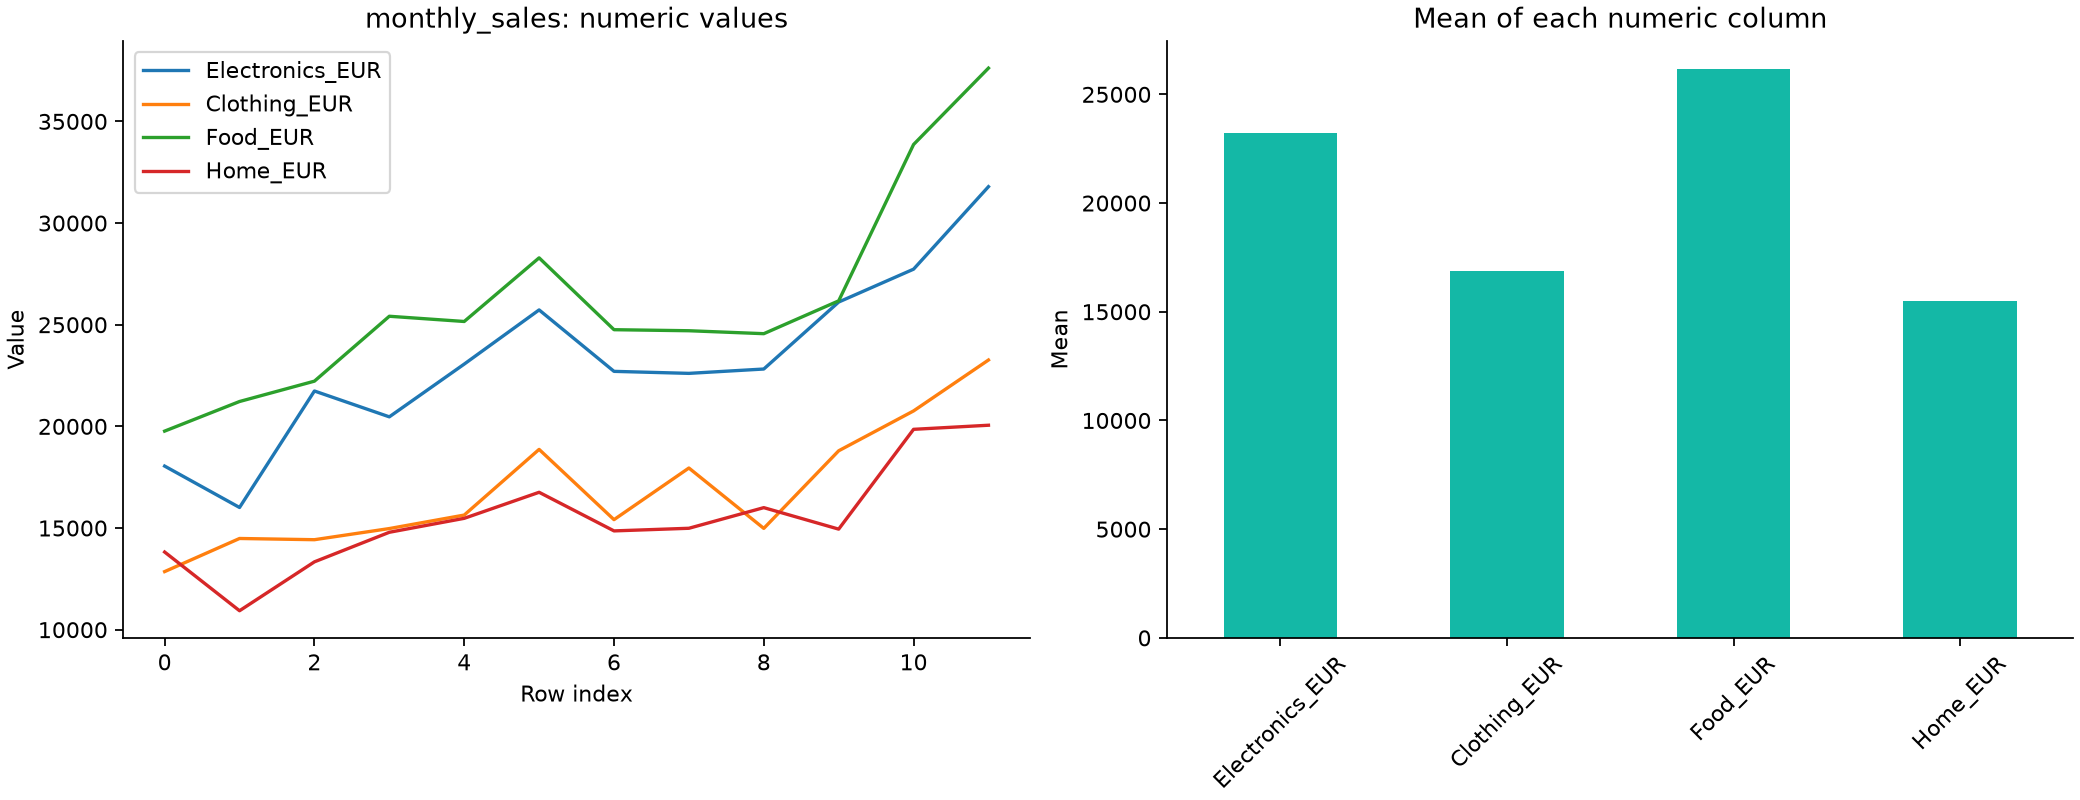

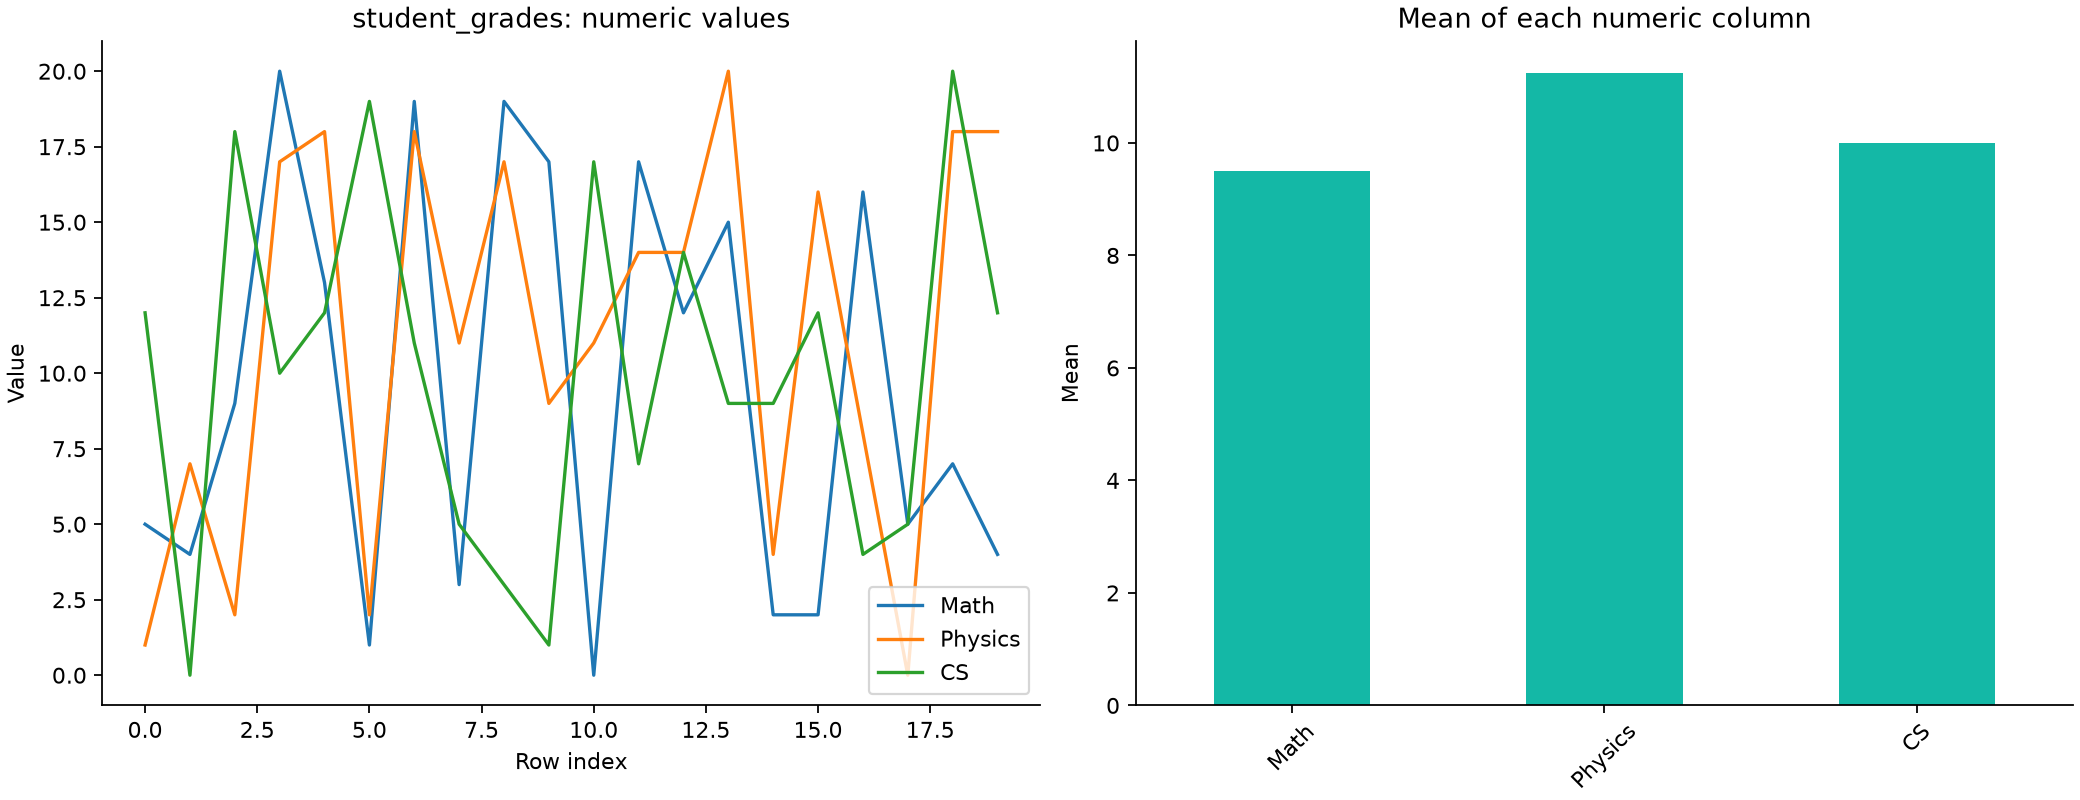

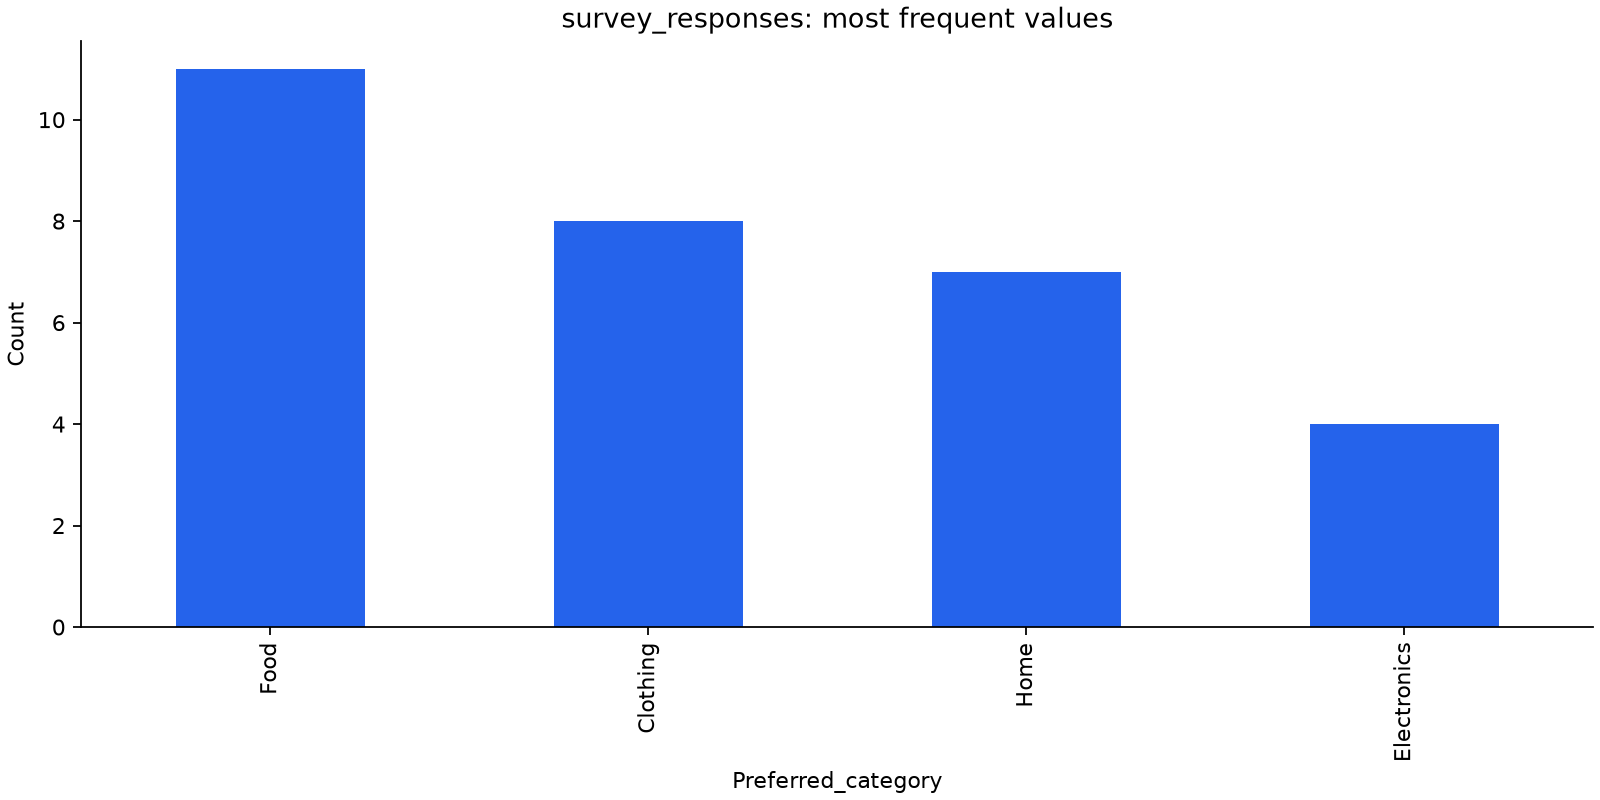

In [2]:
def exercise_0(csv_dir):
    """Read each supplied CSV with Pandas and plot its numeric columns."""
    files = sorted(Path(csv_dir).glob("*.csv"))
    if not files:
        print("Exercise 0: no supplied CSV files were found. Put them in data/ "
              "and rerun, or pass --csv-dir PATH. No source data is invented.")
        return {}

    tables = {}
    for path in files:
        df = pd.read_csv(path)
        tables[path.name] = df
        print(f"\nExercise 0: {path.name}, shape={df.shape}")
        print(df.head().to_string(index=False))
        numeric = df.select_dtypes(include="number")
        if numeric.empty:
            print("No numeric columns: plotting counts of the first column.")
            if df.shape[1] == 0:
                continue
            fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
            df.iloc[:, 0].value_counts().head(20).plot.bar(ax=ax, color=COLORS[0])
            ax.set(title=f"{path.stem}: most frequent values", ylabel="Count")
        else:
            fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
            numeric.plot(ax=axes[0], linewidth=1.5)
            axes[0].set(title=f"{path.stem}: numeric values", xlabel="Row index",
                        ylabel="Value")
            numeric.mean().plot.bar(ax=axes[1], color=COLORS[1])
            axes[1].set(title="Mean of each numeric column", ylabel="Mean")
            axes[1].tick_params(axis="x", labelrotation=45)
        fig.savefig(OUTPUT / f"exercise_0_{path.stem}.png")
        plt.close(fig)
    return tables


csv_tables = exercise_0(Path.cwd() / 'data')


## Exercise 1 — Student Grades Analysis

`integers(0, 21)` includes both 0 and 20. Each student's average uses only the three subjects. The bar chart uses subject means across all 20 students; the histogram uses the 20 individual averages and 10 bins. Ties in the top three are ordered by student number.


Exercise 1: student grades
         Math  Physics  CS  Average
Student                            
S01         1       16  13    10.00
S02         9        9  18    12.00
S03         1       14   4     6.33
S04         1       11  20    10.67
S05        15       15  15    15.00
S06        16       10   2     9.33
S07        17        9  10    12.00
S08         7        3  19     9.67
S09        16       13   8    12.33
S10        17       11   9    12.33
S11         9        4   1     4.67
S12        11       18   1    10.00
S13        18       17   5    13.33
S14        13        3  15    10.33
S15        14        7   1     7.33
S16        20        9  18    15.67
S17        14       16  15    15.00
S18         4        7   9     6.67
S19        10        0  11     7.00
S20         3       15  14    10.67

Top 3 students
         Math  Physics  CS  Average
Student                            
S16        20        9  18    15.67
S05        15       15  15    15.00
S17        14       

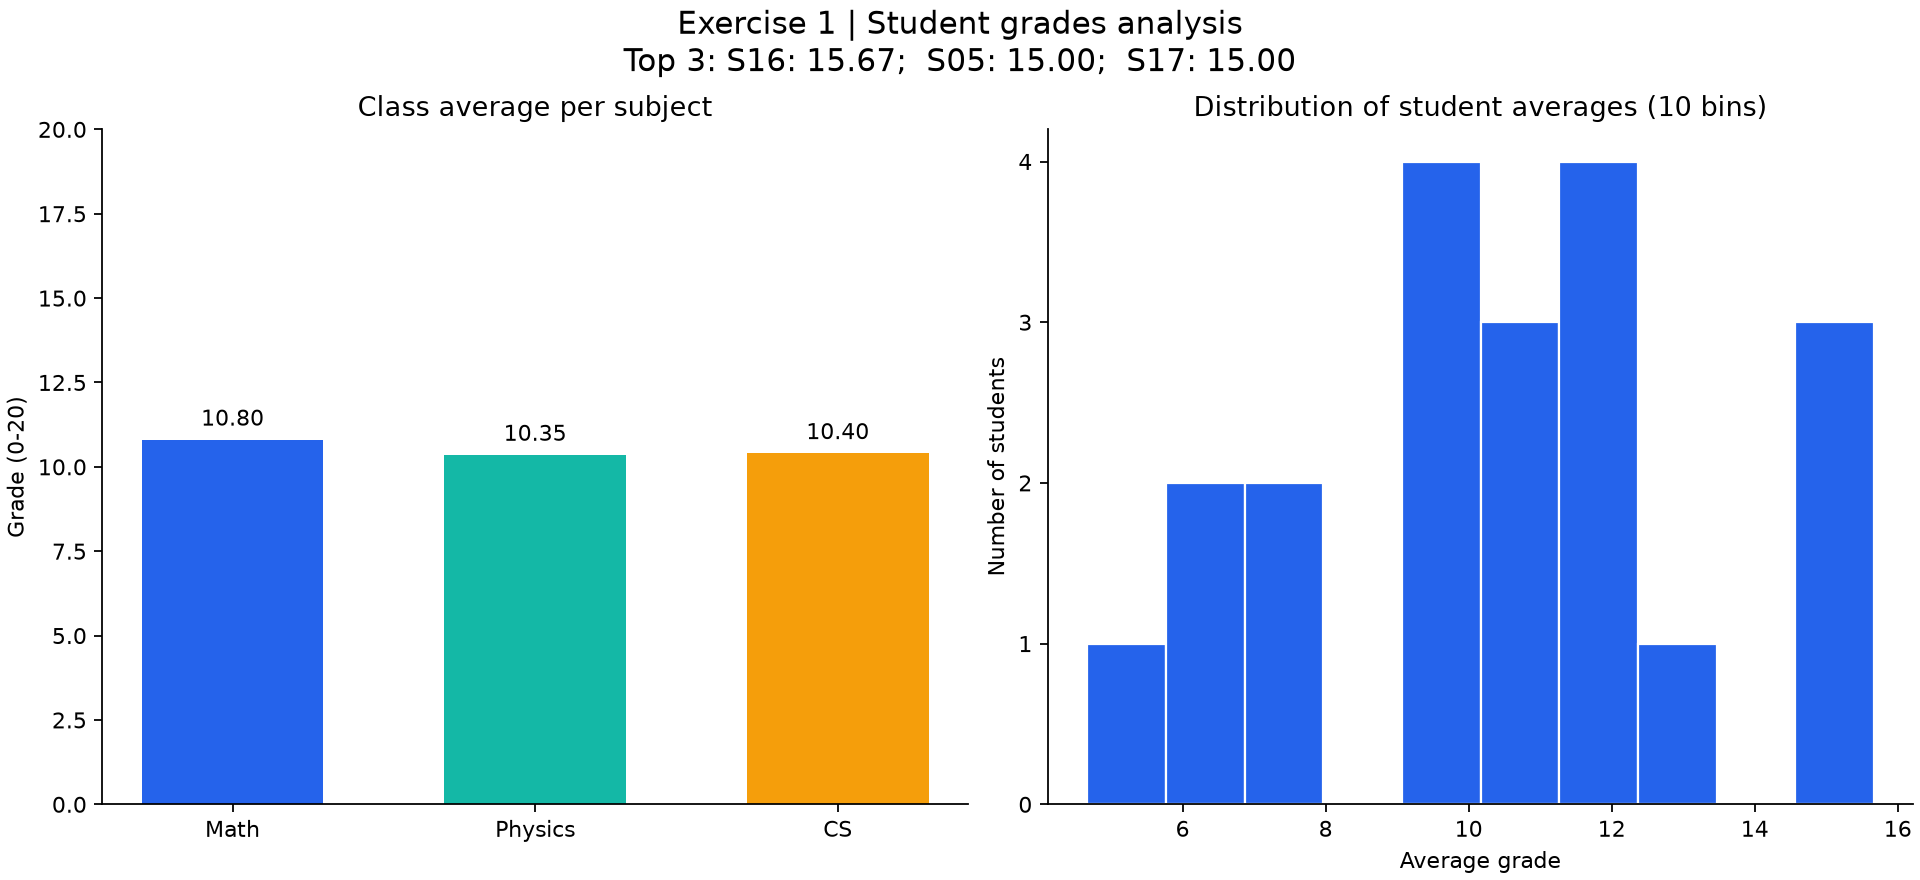

In [3]:
def exercise_1():
    """Generate grades, compute averages and top three, and draw both plots."""
    rng = np.random.default_rng(42)
    subjects = ["Math", "Physics", "CS"]
    students = [f"S{i:02d}" for i in range(1, 21)]
    grades = pd.DataFrame(rng.integers(0, 21, size=(20, 3)),
                          index=pd.Index(students, name="Student"),
                          columns=subjects)
    grades["Average"] = grades[subjects].mean(axis=1)
    # Stable sorting breaks equal-average ties in student-number order.
    top_3 = grades.sort_values("Average", ascending=False, kind="stable").head(3)
    subject_means = grades[subjects].mean()
    print("\nExercise 1: student grades\n" + grades.round(2).to_string())
    print("\nTop 3 students\n" + top_3.round(2).to_string())
    print("\nClass average per subject\n" + subject_means.round(2).to_string())

    fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), layout="constrained")
    bars = axes[0].bar(subjects, subject_means, color=COLORS[:3], width=0.6)
    axes[0].bar_label(bars, fmt="%.2f", padding=4)
    axes[0].set(title="Class average per subject", ylabel="Grade (0-20)",
                ylim=(0, 20))
    axes[1].hist(grades["Average"], bins=10, color=COLORS[0],
                 edgecolor="white")
    axes[1].set(title="Distribution of student averages (10 bins)",
                xlabel="Average grade", ylabel="Number of students")
    axes[1].yaxis.set_major_locator(MaxNLocator(integer=True))
    top_text = ";  ".join(f"{name}: {row.Average:.2f}" for name, row in top_3.iterrows())
    fig.suptitle("Exercise 1 | Student grades analysis\nTop 3: " + top_text,
                 fontsize=14)
    fig.savefig(OUTPUT / "exercise_1_grades.png")
    plt.close(fig)
    grades.to_csv(OUTPUT / "exercise_1_grades.csv")
    return grades, top_3, subject_means


grades, top_3, subject_means = exercise_1()


## Exercise 3 — Retail Sales Dashboard

The matrix has axes `(month, store, category)` and shape `(12, 5, 4)`. Sales are whole euros from EUR 5,000 through EUR 50,000 inclusive. Reshaping to `(60, 4)` preserves month/store order for the MultiIndex. The best pair is the store/category combination with the greatest annual total. Monthly evolution is the total across every store and category.


Exercise 3: matrix shape=(12, 5, 4)

MultiIndex DataFrame (first 5 rows)
               Electronics  Clothing   Food   Home
month store                                       
1     Store 1         9016     39828  34456  24749
      Store 2        24486     43637   8867  36382
      Store 3        14066      9238  28692  48903
      Store 4        38109     39252  37287  40373
      Store 5        28095     10765  42789  25267

Total sales per store (EUR)
store
Store 1    1408563
Store 2    1425519
Store 3    1288384
Store 4    1373705
Store 5    1215073

Total sales per category (EUR)
Electronics    1703345
Clothing       1588784
Food           1714851
Home           1704264

Best annual (store, category) pair: ('Store 4', 'Food'); EUR 433,894


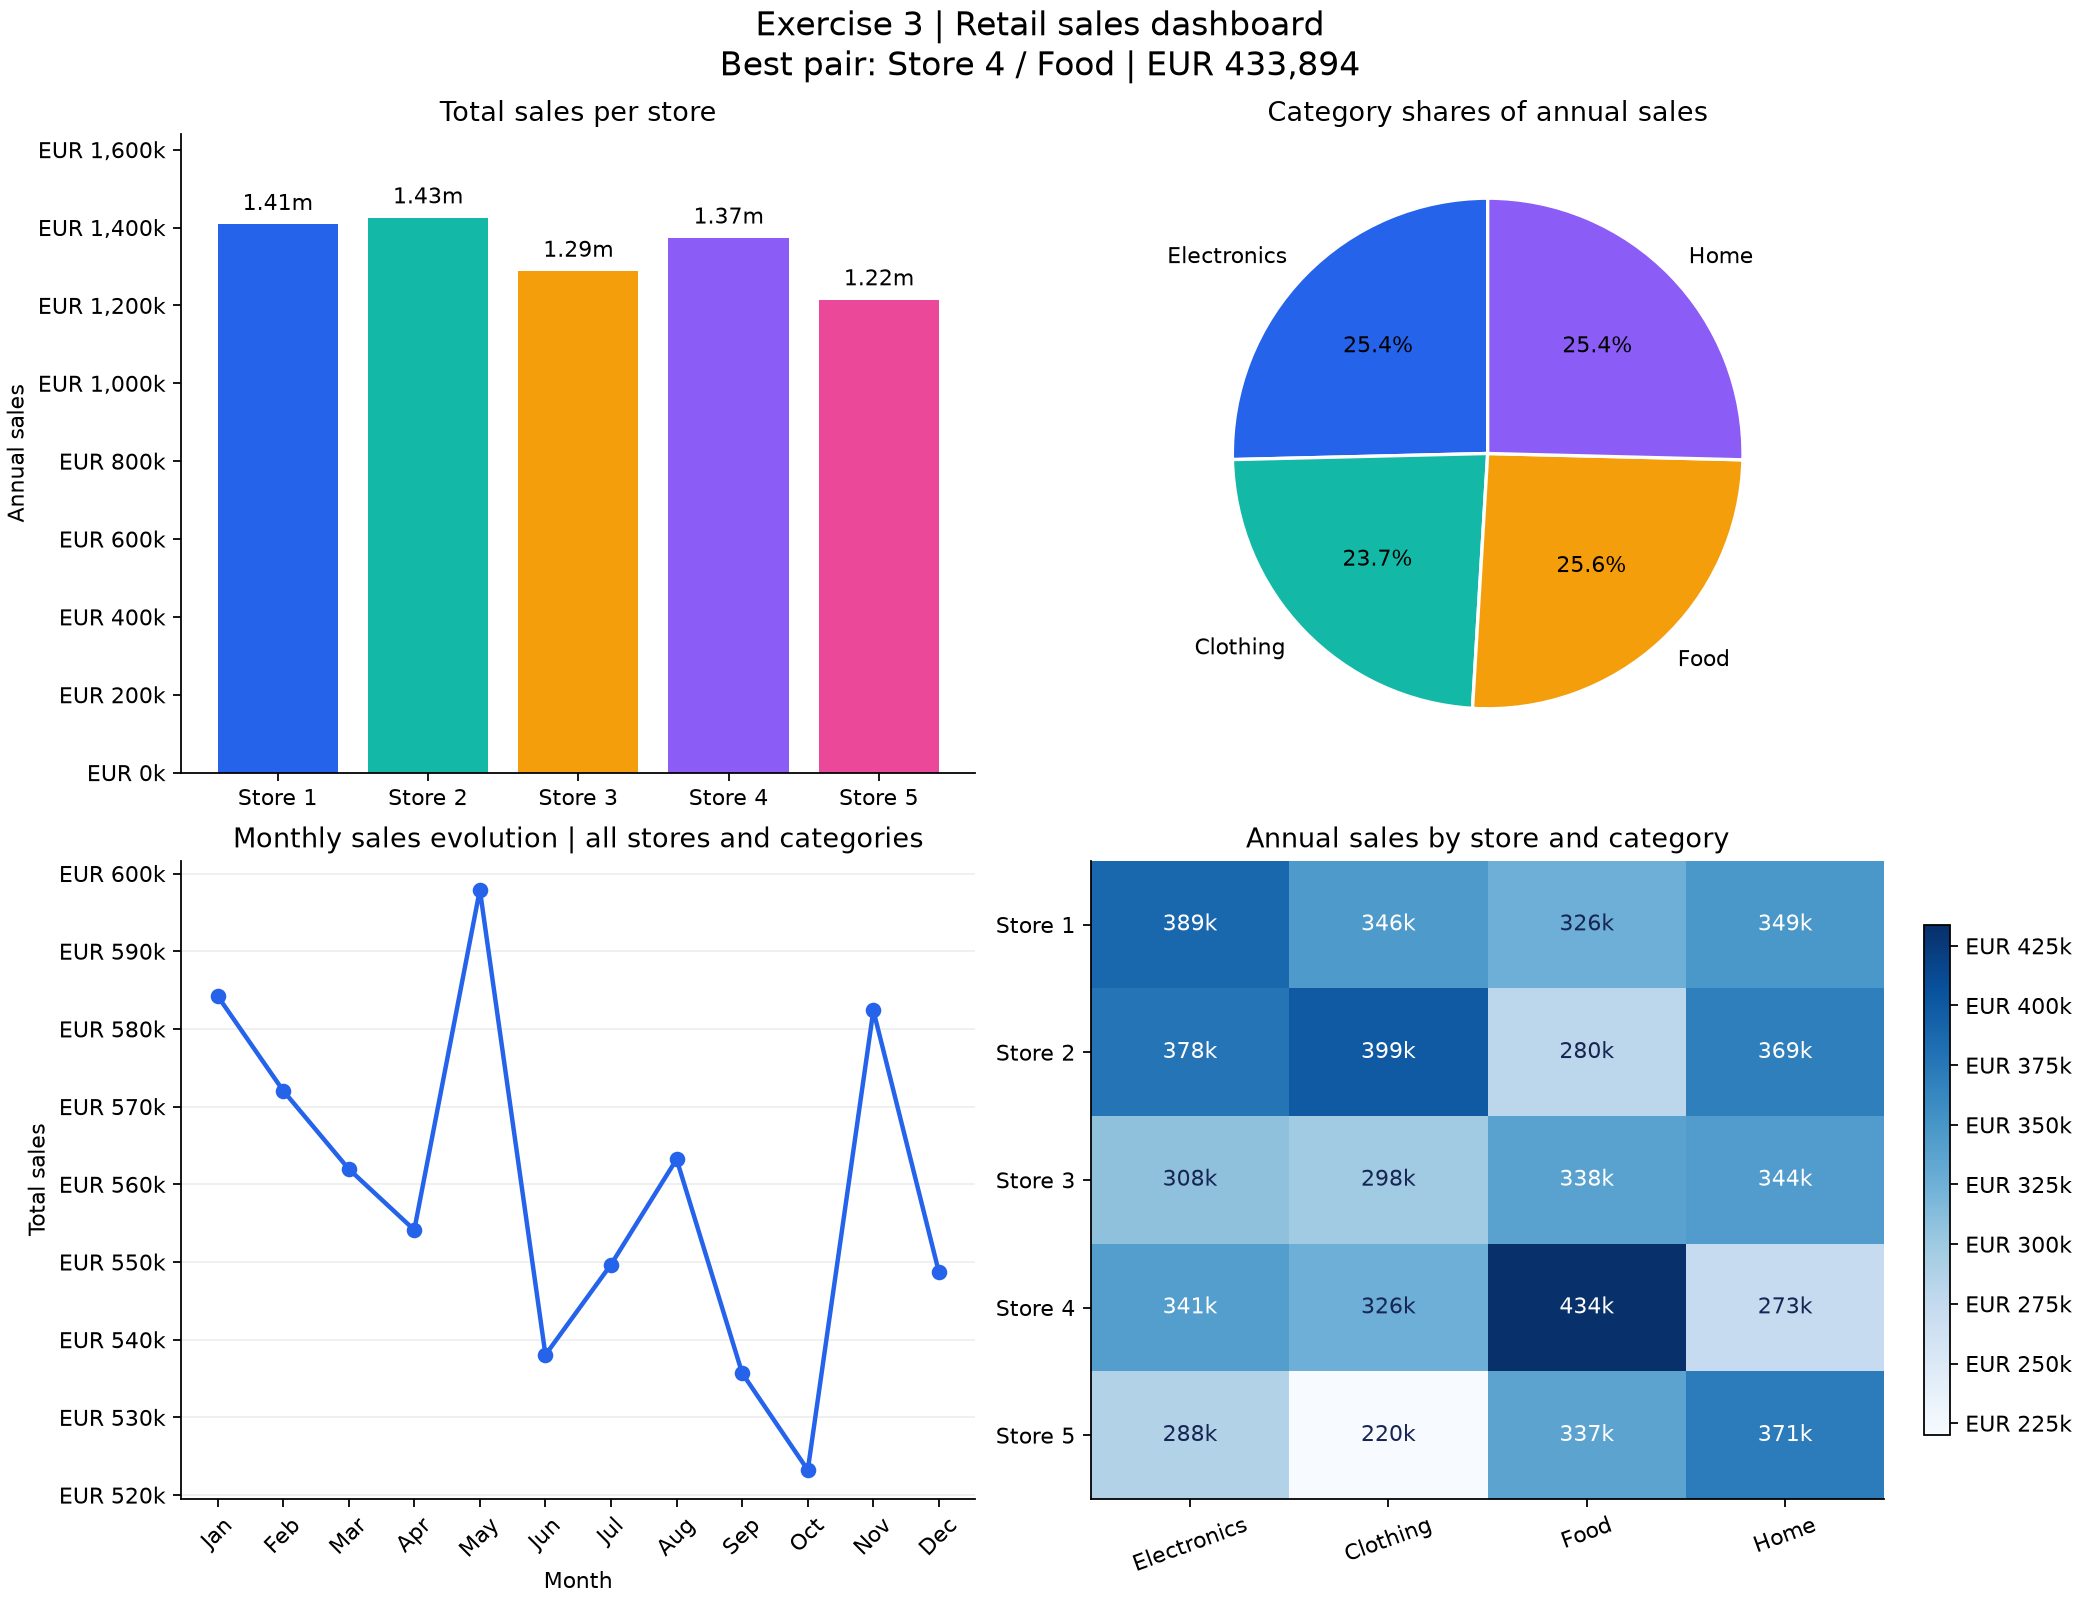

In [4]:
def exercise_3():
    """Aggregate a 12 x 5 x 4 sales matrix and build the 2 x 2 dashboard."""
    rng = np.random.default_rng(42)
    months = list(range(1, 13))
    month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
    stores = [f"Store {i}" for i in range(1, 6)]
    categories = ["Electronics", "Clothing", "Food", "Home"]
    sales_matrix = rng.integers(5_000, 50_001, size=(12, 5, 4))
    index = pd.MultiIndex.from_product([months, stores], names=["month", "store"])
    sales = pd.DataFrame(sales_matrix.reshape(60, 4), index=index,
                         columns=categories)
    store_category = sales.groupby(level="store").sum()
    total_per_store = store_category.sum(axis=1)
    total_per_category = sales.sum(axis=0)
    monthly_total = sales.groupby(level="month").sum().sum(axis=1)
    # Best pair means the highest annual sales for a store/category combination.
    best_pair = store_category.stack().idxmax()
    best_value = int(store_category.loc[best_pair])
    print(f"\nExercise 3: matrix shape={sales_matrix.shape}")
    print("\nMultiIndex DataFrame (first 5 rows)\n" + sales.head().to_string())
    print("\nTotal sales per store (EUR)\n" + total_per_store.to_string())
    print("\nTotal sales per category (EUR)\n" + total_per_category.to_string())
    print(f"\nBest annual (store, category) pair: {best_pair}; EUR {best_value:,}")

    fig, axes = plt.subplots(2, 2, figsize=(13, 10), layout="constrained")
    bars = axes[0, 0].bar(stores, total_per_store, color=COLORS)
    axes[0, 0].bar_label(bars, labels=[f"{v / 1e6:.2f}m" for v in total_per_store],
                          padding=4)
    axes[0, 0].set(title="Total sales per store", ylabel="Annual sales")
    axes[0, 0].margins(y=0.15)
    axes[0, 0].yaxis.set_major_formatter(EUROS)
    axes[0, 1].pie(total_per_category, labels=categories, autopct="%.1f%%",
                   startangle=90, colors=COLORS[:4],
                   wedgeprops={"edgecolor": "white", "linewidth": 1.5})
    axes[0, 1].set_title("Category shares of annual sales")
    axes[1, 0].plot(months, monthly_total, marker="o", color=COLORS[0], linewidth=2)
    axes[1, 0].set(title="Monthly sales evolution | all stores and categories",
                   xlabel="Month", ylabel="Total sales", xticks=months,
                   xticklabels=month_labels)
    axes[1, 0].tick_params(axis="x", labelrotation=45)
    axes[1, 0].yaxis.set_major_formatter(EUROS)
    axes[1, 0].grid(axis="y", alpha=0.2)
    heat = axes[1, 1].imshow(store_category.to_numpy(), cmap="Blues", aspect="auto")
    axes[1, 1].set(title="Annual sales by store and category", xticks=range(4),
                   xticklabels=categories, yticks=range(5), yticklabels=stores)
    axes[1, 1].tick_params(axis="x", labelrotation=20)
    midpoint = (store_category.to_numpy().min() + store_category.to_numpy().max()) / 2
    for row in range(5):
        for col in range(4):
            value = store_category.iloc[row, col]
            axes[1, 1].text(col, row, f"{value / 1000:.0f}k", ha="center", va="center",
                             color="white" if value > midpoint else "#172554")
    fig.colorbar(heat, ax=axes[1, 1], format=EUROS, shrink=0.8)
    fig.suptitle("Exercise 3 | Retail sales dashboard\n"
                 f"Best pair: {best_pair[0]} / {best_pair[1]} | EUR {best_value:,}",
                 fontsize=15)
    fig.savefig(OUTPUT / "exercise_3_sales_dashboard.png")
    plt.close(fig)
    sales.to_csv(OUTPUT / "exercise_3_monthly_sales.csv")
    store_category.to_csv(OUTPUT / "exercise_3_store_category_totals.csv")
    total_per_store.to_csv(OUTPUT / "exercise_3_store_totals.csv", header=["Sales_EUR"])
    total_per_category.to_csv(OUTPUT / "exercise_3_category_totals.csv", header=["Sales_EUR"])
    return sales_matrix, sales, store_category, total_per_store, total_per_category


sales_matrix, sales, store_category, store_totals, category_totals = exercise_3()


## Exercise 6 — Image Processing with NumPy + Pandas + Matplotlib

A synthetic grayscale image is used, as allowed by the exercise. Its pixel matrix is a Pandas DataFrame. `mean(axis=1)` gives a mean for each row and `mean(axis=0)` a mean for each column.

**Brightest region:** the contiguous 16 × 16 square with the highest mean brightness (a smaller square for tiny images). The brightest row, column, and first maximum pixel are also reported. Coordinates are zero-based and region endpoints are inclusive.

Thresholding uses the exact rule **pixel > 128 → 255; otherwise → 0**. For a real image, call `exercise_6('image.png')`; normalized PNG values are converted to the 0–255 scale before thresholding.


Exercise 6: synthetic grayscale image
Shape: (128, 192); dtype: uint8; min: 12; max: 234

Per-row mean brightness
row
0       71.38
1       72.55
2       72.51
3       73.17
4       74.45
5       75.97
6       75.76
7       77.34
8       77.07
9       78.19
10      79.45
11      81.55
12      82.68
13      84.49
14      84.92
15      86.76
16      87.62
17      88.09
18      90.59
19      91.07
20      91.26
21      93.94
22      94.40
23      96.48
24      96.50
25      97.61
26      99.18
27     101.76
28     101.69
29     103.03
30     105.72
31     104.70
32     105.97
33     107.86
34     106.49
35     108.14
36     109.37
37     109.66
38     108.80
39     109.34
40     109.62
41     110.33
42     110.85
43     111.36
44     110.60
45     110.56
46     109.74
47     109.81
48     108.50
49     108.45
50     109.76
51     107.12
52     107.24
53     106.56
54     106.23
55     105.66
56     104.72
57     105.28
58     102.27
59     101.62
60     102.05
61     101.10
62      99.56

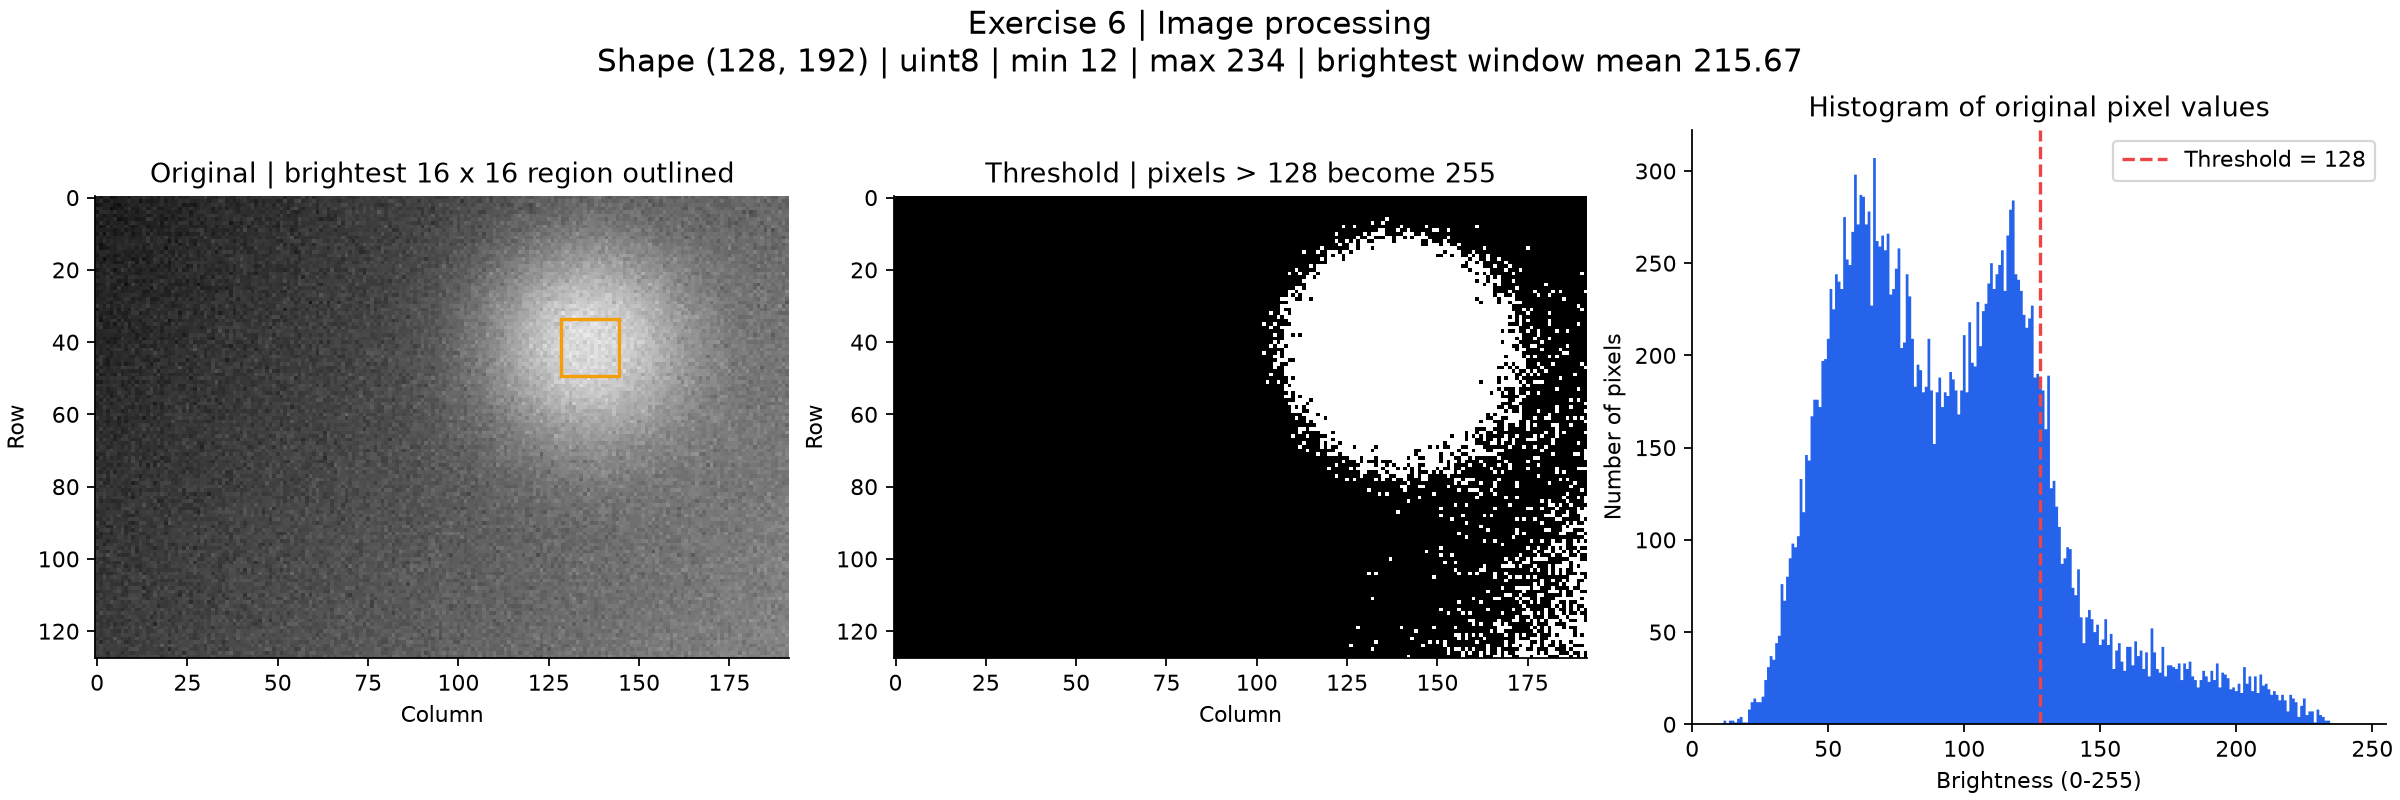

In [5]:
def exercise_6(image_path=None):
    """Use a grayscale NumPy array and Pandas to analyze pixel brightness."""
    if image_path is None:
        # A reproducible synthetic grayscale image, explicitly allowed by the task.
        rng = np.random.default_rng(42)
        y, x = np.mgrid[0:128, 0:192]
        values = (30 + 75 * x / 191 + 30 * y / 127
                  + 130 * np.exp(-((x - 135) ** 2 + (y - 40) ** 2) / (2 * 20 ** 2))
                  + rng.normal(0, 8, size=x.shape))
        image = np.clip(values, 0, 255).astype(np.uint8)
        source = "synthetic grayscale image"
    else:
        image = plt.imread(image_path)
        # PNGs often load as floating-point arrays in [0, 1].
        if np.issubdtype(image.dtype, np.floating):
            if not np.isfinite(image).all() or image.min() < 0 or image.max() > 1:
                raise ValueError("Floating-point images must contain finite values in [0, 1].")
            image = image * 255
        if image.ndim == 3 and image.shape[2] in (3, 4):
            image = image[..., :3] @ np.array([0.299, 0.587, 0.114])
        if image.ndim != 2:
            raise ValueError("Use a grayscale, RGB, or RGBA image.")
        image = np.clip(image, 0, 255).round().astype(np.uint8)
        source = Path(image_path).name

    pixels = pd.DataFrame(image)
    pixels.index.name = "row"
    pixels.columns.name = "column"
    row_means = pixels.mean(axis=1)
    column_means = pixels.mean(axis=0)
    brightest_row = int(row_means.idxmax())
    brightest_column = int(column_means.idxmax())
    brightest_pixel = np.unravel_index(image.argmax(), image.shape)
    # Define "region" as a contiguous 16 x 16 window (smaller for tiny inputs).
    # Two rolling means compute every full square window's mean brightness.
    size = min(16, *image.shape)
    region_means = (pixels.rolling(size, min_periods=size).mean()
                   .T.rolling(size, min_periods=size).mean().T)
    bottom, right = region_means.stack().idxmax()
    top, left = int(bottom - size + 1), int(right - size + 1)
    region_mean = float(region_means.loc[bottom, right])
    thresholded = np.where(image > 128, 255, 0).astype(np.uint8)
    print(f"\nExercise 6: {source}")
    print(f"Shape: {image.shape}; dtype: {image.dtype}; min: {image.min()}; max: {image.max()}")
    print("\nPer-row mean brightness\n" + row_means.round(2).to_string())
    print("\nPer-column mean brightness\n" + column_means.round(2).to_string())
    print(f"\nBrightest row: {brightest_row} (mean {row_means.max():.2f})")
    print(f"Brightest column: {brightest_column} (mean {column_means.max():.2f})")
    print(f"First brightest pixel (row, column): {brightest_pixel}; value {image.max()}")
    print(f"Brightest {size} x {size} region: rows {top}-{bottom}, columns {left}-{right} "
          f"(inclusive); mean {region_mean:.2f}. All coordinates are zero-based.")
    print(f"Pixels strictly above 128: {(image > 128).mean():.2%}")

    fig, axes = plt.subplots(1, 3, figsize=(15, 5), layout="constrained")
    axes[0].imshow(image, cmap="gray", vmin=0, vmax=255)
    axes[0].add_patch(Rectangle((left - 0.5, top - 0.5), size, size,
                                linewidth=1.5, edgecolor=COLORS[2], facecolor="none"))
    axes[0].set(title=f"Original | brightest {size} x {size} region outlined",
                xlabel="Column", ylabel="Row")
    axes[1].imshow(thresholded, cmap="gray", vmin=0, vmax=255)
    axes[1].set(title="Threshold | pixels > 128 become 255",
                xlabel="Column", ylabel="Row")
    axes[2].hist(image.ravel(), bins=256, range=(-0.5, 255.5),
                 color=COLORS[0], histtype="stepfilled")
    axes[2].axvline(128, color="#ef4444", linestyle="--", label="Threshold = 128")
    axes[2].set(title="Histogram of original pixel values", xlabel="Brightness (0-255)",
                ylabel="Number of pixels", xlim=(0, 255))
    axes[2].legend()
    fig.suptitle(f"Exercise 6 | Image processing\n"
                 f"Shape {image.shape} | {image.dtype} | min {image.min()} | max {image.max()} | "
                 f"brightest window mean {region_mean:.2f}", fontsize=14)
    fig.savefig(OUTPUT / "exercise_6_image_processing.png")
    plt.close(fig)
    plt.imsave(OUTPUT / "exercise_6_original.png", image, cmap="gray", vmin=0, vmax=255)
    plt.imsave(OUTPUT / "exercise_6_thresholded.png", thresholded,
               cmap="gray", vmin=0, vmax=255)
    pixels.to_csv(OUTPUT / "exercise_6_pixels.csv")
    row_means.to_csv(OUTPUT / "exercise_6_row_means.csv", header=["Mean_brightness"])
    column_means.to_csv(OUTPUT / "exercise_6_column_means.csv", header=["Mean_brightness"])
    return image, pixels, row_means, column_means, thresholded


image, pixels, row_means, column_means, thresholded = exercise_6()
